# Phase 1 — Monte Carlo risk engine

**Purpose.** Your `01_R_calculator` Section 3 draws one smooth growth curve.
Real trading is not smooth. This notebook simulates thousands of possible
futures of your rules and shows the whole range: typical result, bad luck,
drawdowns and losing streaks.

**Mission.** Answer four questions with probabilities, not single numbers:

1. Where could the account be after 300 trades?
2. How deep will the drawdowns go?
3. How long will the losing streaks be?
4. What do gaps, the cash cap, a higher risk setting and correlated slots do?

**The linear algebra.** One matrix `R` of shape (paths, trades) holds every
trade of every future. One `cumprod` along the columns turns it into equity.
A Cholesky factor makes two slots move together.

**Read this first.** The inputs below (23% win rate, 8R average winner) are
borrowed from two star traders. They are **assumptions, not your results**.
The output is only as good as those inputs. Phase 2 replaces them with your
own trade log. This is a study tool, not advice.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import lab_style as ls
import mc_engine as mc

ls.use_lab_style()
dollars = FuncFormatter(lambda v, _: f"${v:,.0f}")

In [2]:
# ============================================================
# KEY IN HERE  --  your system, as numbers
# ============================================================
START_EQUITY = 2000     # account in $
RISK_PCT     = 0.01     # 1R as a fraction of equity (your rule: 1%)
WIN_RATE     = 0.23     # assumed, from Luk / Qullamaggie
AVG_WIN_R    = 8.0      # assumed average winner in R
TRADES       = 300      # trades per simulated future
PATHS        = 10_000   # number of simulated futures
SEED         = 42       # same seed = same random numbers = same result

rules = mc.Rules(start_equity=START_EQUITY, risk_pct=RISK_PCT,
                 win_rate=WIN_RATE, avg_win_R=AVG_WIN_R)
print(f"Expectancy = {rules.expectancy_R:+.2f} R per trade")

Expectancy = +1.07 R per trade


## Step 1 — One future, with a plain loop

Start simple. One trade at a time: draw a random number, decide win or loss,
update the account. Winners are +8R exactly, losers −1R exactly.

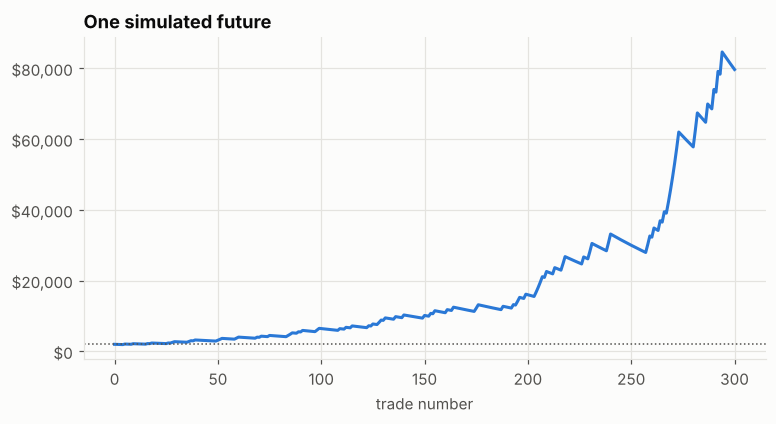

This future ends at $79,672. Change SEED and it changes.


In [3]:
rng = np.random.default_rng(SEED)

equity = START_EQUITY
one_path = [equity]
for trade in range(TRADES):
    if rng.random() < WIN_RATE:
        result_R = AVG_WIN_R
    else:
        result_R = -1.0
    equity = equity * (1 + result_R * RISK_PCT)
    one_path.append(equity)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(one_path, color=ls.BLUE)
ax.axhline(START_EQUITY, color=ls.TEXT_SOFT, lw=1, ls=":")
ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel("trade number"); ax.set_title("One simulated future")
plt.show()
print(f"This future ends at ${one_path[-1]:,.0f}. Change SEED and it changes.")

One future tells you little. It is one roll of the dice. You need thousands.

## Step 2 — Ten thousand futures, with one matrix

Replace the loop with a matrix. `R` has one row per future and one column per
trade. `np.cumprod(..., axis=1)` multiplies along each row, which compounds
every future at once.

The engine also makes winners **vary in size** (a lognormal spread with mean
8R: many modest winners, a few very large), which is closer to how a
trend-following method pays.

In [4]:
rng = np.random.default_rng(SEED)
R = mc.simulate_R(rules, PATHS, TRADES, rng)
equity = mc.equity_paths(R, START_EQUITY, RISK_PCT)

print("R matrix shape     :", R.shape, " (futures, trades)")
print("equity matrix shape:", equity.shape, "(one extra column = the start)")
print(f"mean of all {R.size:,} trades: {R.mean():+.2f} R "
      f"(theory {rules.expectancy_R:+.2f} R)")
print("\nFirst future, first 12 trades in R:")
print(R[0, :12].round(1))

R matrix shape     : (10000, 300)  (futures, trades)
equity matrix shape: (10000, 301) (one extra column = the start)


mean of all 3,000,000 trades: +1.07 R (theory +1.07 R)

First future, first 12 trades in R:
[-1.  -1.  -1.  -1.   3.3 -1.  -1.  -1.  12.6 -1.  -1.  -1. ]


## Chart 1 — The fan chart: where could the account be?

The shaded bands hold the middle 50% and middle 90% of futures. The dashed
line is the smooth curve from your Section 3. The y-axis is a log scale, so
equal distances mean equal percentage growth.

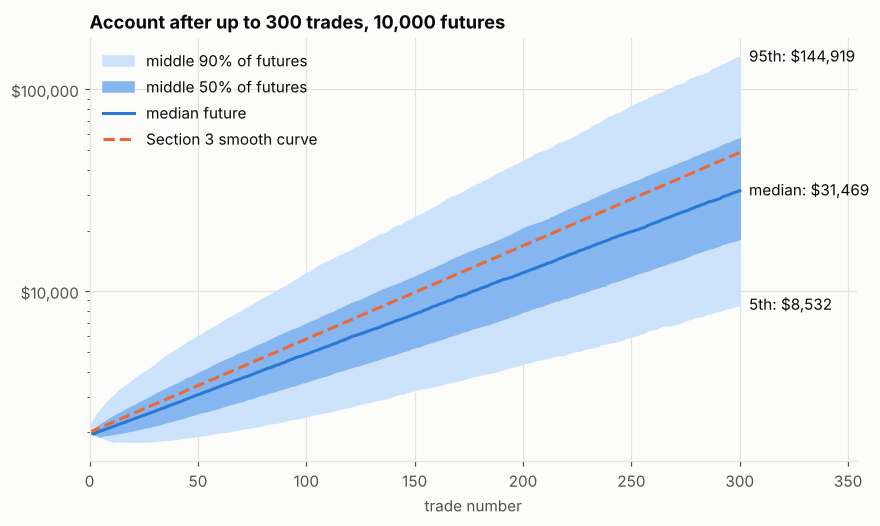

Smooth curve ends at $48,720.
Share of futures that end below the smooth curve: 69%


In [5]:
x = np.arange(TRADES + 1)
p5, p25, p50, p75, p95 = np.percentile(equity, [5, 25, 50, 75, 95], axis=0)
smooth = START_EQUITY * (1 + rules.expectancy_R * RISK_PCT) ** x

fig, ax = plt.subplots(figsize=(9, 5))
ax.fill_between(x, p5, p95, color=ls.BLUE_BAND_OUTER, label="middle 90% of futures")
ax.fill_between(x, p25, p75, color=ls.BLUE_BAND_INNER, label="middle 50% of futures")
ax.plot(x, p50, color=ls.BLUE, label="median future")
ax.plot(x, smooth, color=ls.ORANGE, ls="--", label="Section 3 smooth curve")
ax.set_yscale("log"); ax.yaxis.set_major_formatter(dollars)
for value, name in [(p95[-1], "95th"), (p50[-1], "median"), (p5[-1], "5th")]:
    ax.annotate(f"{name}: ${value:,.0f}", (TRADES, value),
                textcoords="offset points", xytext=(6, -3), color=ls.TEXT)
ax.set_xlim(0, TRADES * 1.18)
ax.set_xlabel("trade number")
ax.set_title(f"Account after up to {TRADES} trades, {PATHS:,} futures")
ax.legend(loc="upper left")
plt.show()

print(f"Smooth curve ends at ${smooth[-1]:,.0f}.")
print(f"Share of futures that end below the smooth curve: "
      f"{100 * np.mean(equity[:, -1] < smooth[-1]):.0f}%")

The smooth curve is not the typical outcome. Most futures finish below it,
because a few very lucky futures pull the average up. Plan on the median and
the 5th percentile, not on the smooth curve.

## Chart 2 — Drawdown: how deep is the worst fall?

Maximum drawdown is the largest fall from a peak to a later low, in each future.

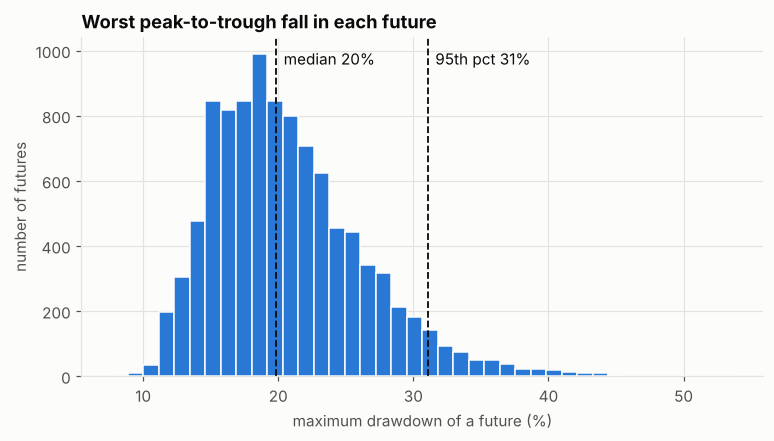

P(max drawdown >= 10%) =  99.9%
P(max drawdown >= 20%) =  48.8%
P(max drawdown >= 30%) =   6.6%
P(max drawdown >= 50%) =   0.0%


In [6]:
dd = 100 * mc.max_drawdown(equity)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(dd, bins=40, color=ls.BLUE, edgecolor=ls.SURFACE, linewidth=1)
for value, name in [(np.median(dd), "median"), (np.percentile(dd, 95), "95th pct")]:
    ax.axvline(value, color=ls.TEXT, lw=1.2, ls="--")
    ax.annotate(f"{name} {value:.0f}%", (value, ax.get_ylim()[1] * 0.92),
                textcoords="offset points", xytext=(5, 0), color=ls.TEXT)
ax.set_xlabel("maximum drawdown of a future (%)"); ax.set_ylabel("number of futures")
ax.set_title("Worst peak-to-trough fall in each future")
plt.show()

for level in [10, 20, 30, 50]:
    print(f"P(max drawdown >= {level}%) = {np.mean(dd >= level) * 100:5.1f}%")

## Chart 3 — Losing streaks: how many losers in a row?

With a 23% win rate, long streaks are normal. Your rulebook says the chance
of 10 losers in a row is 0.77¹⁰ = 7%. That is the chance for **one fixed
block of 10 trades**. Over 300 trades there are many blocks.

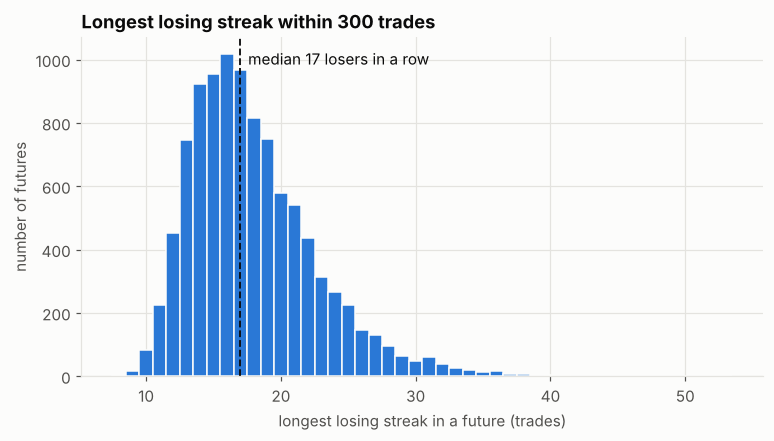

P(at least one streak of 10+ losers in 300 trades) = 99.8%
P(at least one streak of 20+ losers) = 30.5%
A median streak of 17 losers costs about 16% of the account at 1.0% risk.


In [7]:
streak = mc.longest_losing_streak(R)

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(streak.min(), streak.max() + 2) - 0.5
ax.hist(streak, bins=bins, color=ls.BLUE, edgecolor=ls.SURFACE, linewidth=1)
ax.axvline(np.median(streak), color=ls.TEXT, lw=1.2, ls="--")
ax.annotate(f"median {np.median(streak):.0f} losers in a row",
            (np.median(streak), ax.get_ylim()[1] * 0.92),
            textcoords="offset points", xytext=(5, 0), color=ls.TEXT)
ax.set_xlabel("longest losing streak in a future (trades)")
ax.set_ylabel("number of futures")
ax.set_title(f"Longest losing streak within {TRADES} trades")
plt.show()

print(f"P(at least one streak of 10+ losers in {TRADES} trades) = "
      f"{100 * np.mean(streak >= 10):.1f}%")
print(f"P(at least one streak of 20+ losers) = {100 * np.mean(streak >= 20):.1f}%")
print(f"A median streak of {np.median(streak):.0f} losers costs about "
      f"{100 * (1 - (1 - RISK_PCT) ** np.median(streak)):.0f}% of the account at "
      f"{RISK_PCT:.1%} risk.")

## Step 3 — Add the real-world rules, one at a time

Each scenario changes one thing from the baseline, so you can see what each
rule costs.

| Scenario | Change | Source |
|---|---|---|
| Baseline | the inputs above | — |
| Gaps | 5% of losers open past the stop and lose 2.5R | rule S4; the 5% is a guess |
| Cash cap | 30% of trades are cut to half size | rule S2; the 30% is a guess |
| Risk 2.5% | `risk_pct = 0.025`, as keyed in your calculator | your Section 1 cell |
| Half the edge | average winner 4.5R, not 8R | "what if I am not Luk?" |

The gap and cap frequencies are placeholders. Measure them from your trade log.

In [8]:
scenarios = {
    "Baseline (1% risk)": dict(),
    "+ gaps": dict(gap_prob=0.05, gap_R=2.5),
    "+ cash cap": dict(capped_prob=0.30, capped_frac=0.5),
    "Risk 2.5%": dict(risk_pct=0.025),
    "Half the edge": dict(avg_win_R=4.5),
}

rows = {}
for name, change in scenarios.items():
    r = mc.Rules(**{**rules.__dict__, **change})
    rng = np.random.default_rng(SEED)          # same luck for every scenario
    R_s = mc.simulate_R(r, PATHS, TRADES, rng)
    eq_s = mc.equity_paths(R_s, r.start_equity, r.risk_pct)
    rows[name] = {"Expectancy (R)": r.expectancy_R, **mc.summarize(eq_s, R_s)}

table = pd.DataFrame(rows).T
table.style.format({c: "{:,.0f}" if "$" in c else "{:.1f}" for c in table.columns}
                   | {"Expectancy (R)": "{:+.2f}"})

,Expectancy (R),"Final equity, 5th pct ($)","Final equity, median ($)","Final equity, 95th pct ($)",P(end below start) %,"Max drawdown, median %","Max drawdown, 95th pct %",P(drawdown >= 30%) %,P(drawdown >= 50%) %,"Losing streak, median"
Baseline (1% risk),+1.07,"8,532","31,469","144,919",0.0,19.8,31.1,6.6,0.0,17.0
+ gaps,+1.01,"7,104","26,464","121,952",0.0,22.0,34.5,12.8,0.1,17.0
+ cash cap,+0.91,"6,778","21,408","84,485",0.0,17.6,27.9,3.0,0.0,17.0
Risk 2.5%,+1.07,"35,999","664,757","17,889,277",0.0,43.3,61.8,95.7,26.0,17.0
Half the edge,+0.27,"1,670","3,732","9,622",10.7,27.4,45.6,38.4,2.5,17.0


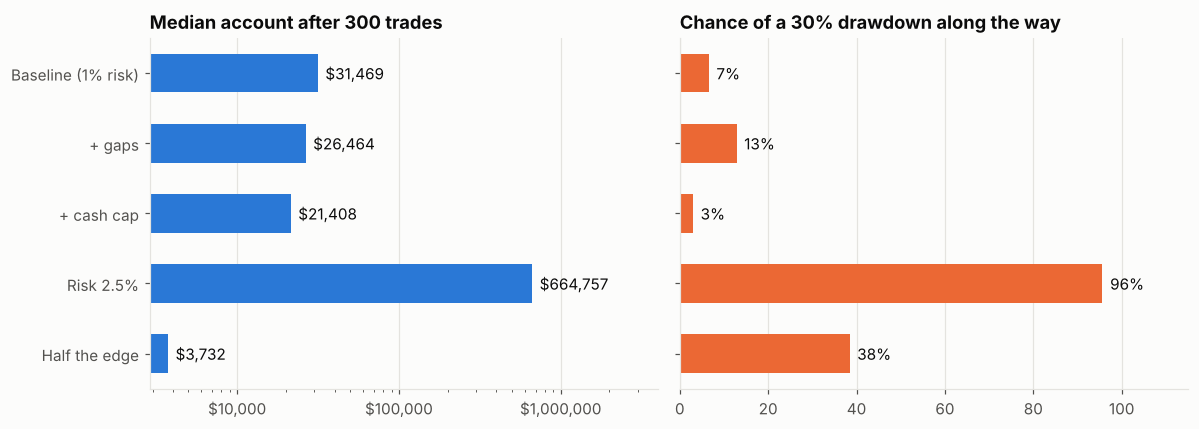

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
names = list(table.index)[::-1]

med = table.loc[names, "Final equity, median ($)"]
axes[0].barh(names, med, color=ls.BLUE, height=0.55)
axes[0].set_xscale("log"); axes[0].xaxis.set_major_formatter(dollars)
axes[0].set_title(f"Median account after {TRADES} trades")
for y, v in enumerate(med):
    axes[0].annotate(f"${v:,.0f}", (v, y), textcoords="offset points",
                     xytext=(5, -4), color=ls.TEXT)
axes[0].set_xlim(right=med.max() * 6)

p30 = table.loc[names, "P(drawdown >= 30%) %"]
axes[1].barh(names, p30, color=ls.ORANGE, height=0.55)
axes[1].set_title("Chance of a 30% drawdown along the way")
axes[1].set_xlim(0, 115); axes[1].set_yticklabels([])
for y, v in enumerate(p30):
    axes[1].annotate(f"{v:.0f}%", (v, y), textcoords="offset points",
                     xytext=(5, -4), color=ls.TEXT)
for ax in axes:
    ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

Read the two charts together. A higher risk setting lifts the median a lot,
and lifts the chance of a deep drawdown with it. "Half the edge" shows how
much the whole picture depends on the borrowed 8R figure.

## Step 4 — Two slots that move together (Cholesky)

Your rule: the two slots must be uncorrelated, or they are one bet. Here both
slots are open in every round. Correlation `ρ` links their win or loss
through a Cholesky factor (see Phase 0, section 5). Same number of trades,
same expectancy; only `ρ` changes.

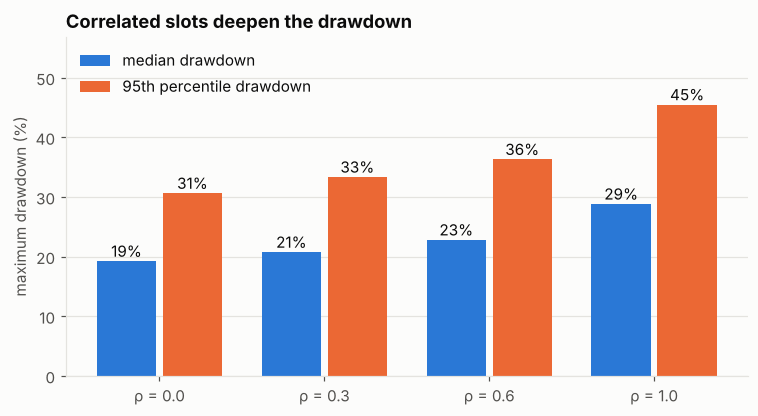

rho = 0.0: both slots lose in the same round 59% of the time
rho = 0.3: both slots lose in the same round 62% of the time
rho = 0.6: both slots lose in the same round 66% of the time
rho = 1.0: both slots lose in the same round 77% of the time


In [10]:
ROUNDS = TRADES // 2            # two trades per round = same total trades
rho_values = [0.0, 0.3, 0.6, 1.0]
dd_by_rho, both_lose = {}, {}

for rho in rho_values:
    rng = np.random.default_rng(SEED)
    eq_2, R_2 = mc.simulate_two_slots(rules, rho, PATHS, ROUNDS, rng)
    dd_by_rho[rho] = 100 * mc.max_drawdown(eq_2)
    both_lose[rho] = 100 * np.mean(R_2 <= -2.0)

fig, ax = plt.subplots(figsize=(8, 4))
positions = np.arange(len(rho_values))
med = [np.median(dd_by_rho[r]) for r in rho_values]
p95 = [np.percentile(dd_by_rho[r], 95) for r in rho_values]
ax.bar(positions - 0.2, med, width=0.36, color=ls.BLUE, label="median drawdown")
ax.bar(positions + 0.2, p95, width=0.36, color=ls.ORANGE, label="95th percentile drawdown")
for xpos, v in list(zip(positions - 0.2, med)) + list(zip(positions + 0.2, p95)):
    ax.annotate(f"{v:.0f}%", (xpos, v), ha="center", textcoords="offset points",
                xytext=(0, 3), color=ls.TEXT)
ax.set_xticks(positions); ax.set_xticklabels([f"ρ = {r}" for r in rho_values])
ax.set_ylabel("maximum drawdown (%)"); ax.grid(axis="x", visible=False)
ax.set_title("Correlated slots deepen the drawdown")
ax.legend(loc="upper left"); ax.set_ylim(0, max(p95) * 1.25)
plt.show()

for rho in rho_values:
    print(f"rho = {rho:.1f}: both slots lose in the same round "
          f"{both_lose[rho]:.0f}% of the time")

## Chart 4 — Risk map: which settings are survivable?

Each cell is the chance of a 30% drawdown within 300 trades, for one
combination of risk per trade and true win rate. Darker is more dangerous.
Find your risk row, then look left: that is what happens if your real win
rate is lower than you hope.

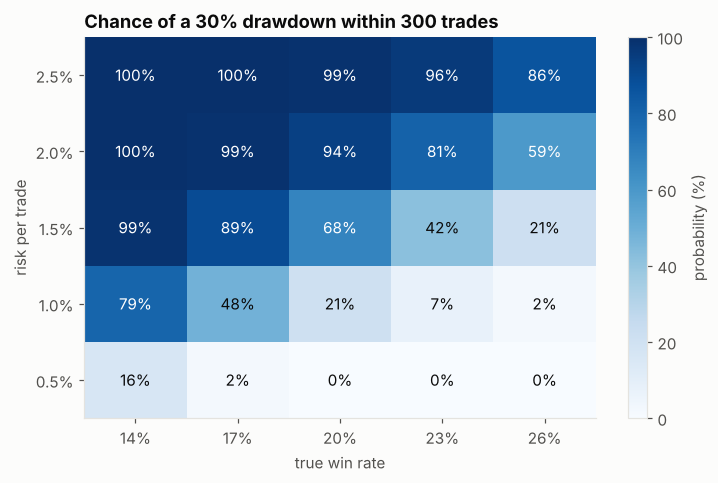

In [11]:
risk_grid = [0.005, 0.01, 0.015, 0.02, 0.025]
win_grid = [0.14, 0.17, 0.20, 0.23, 0.26]
heat = np.zeros((len(risk_grid), len(win_grid)))

for j, wr in enumerate(win_grid):
    r = mc.Rules(**{**rules.__dict__, "win_rate": wr})
    R_h = mc.simulate_R(r, 4000, TRADES, np.random.default_rng(SEED))
    for i, rp in enumerate(risk_grid):
        dd_h = mc.max_drawdown(mc.equity_paths(R_h, START_EQUITY, rp))
        heat[i, j] = 100 * np.mean(dd_h >= 0.30)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
im = ax.imshow(heat, cmap="Blues", vmin=0, vmax=100, aspect="auto", origin="lower")
ax.set_xticks(range(len(win_grid))); ax.set_xticklabels([f"{w:.0%}" for w in win_grid])
ax.set_yticks(range(len(risk_grid))); ax.set_yticklabels([f"{r:.1%}" for r in risk_grid])
for i in range(len(risk_grid)):
    for j in range(len(win_grid)):
        ax.text(j, i, f"{heat[i, j]:.0f}%", ha="center", va="center",
                color="white" if heat[i, j] > 55 else ls.TEXT)
ax.set_xlabel("true win rate"); ax.set_ylabel("risk per trade")
ax.set_title("Chance of a 30% drawdown within 300 trades")
ax.grid(False)
fig.colorbar(im, ax=ax, label="probability (%)")
plt.show()

## Milestones — how likely is each multiple of the account?

Share of futures that have **touched** each multiple by a given trade count,
under the baseline. Remember the inputs are assumptions.

In [12]:
running_peak = np.maximum.accumulate(equity, axis=1) / START_EQUITY
milestones = pd.DataFrame(
    {f"by trade {n}": [100 * np.mean(running_peak[:, n] >= m) for m in [2, 5, 10, 25]]
     for n in [50, 100, 200, 300]},
    index=[f"{m}x  (${m * START_EQUITY:,})" for m in [2, 5, 10, 25]])
milestones.round(0).astype(int).astype(str) + "%"

,by trade 50,by trade 100,by trade 200,by trade 300
"2x ($4,000)",27%,72%,98%,100%
"5x ($10,000)",0%,11%,66%,94%
"10x ($20,000)",0%,1%,28%,74%
"25x ($50,000)",0%,0%,4%,32%


## What this notebook shows

All figures below come from the baseline run above (seed 42, 10,000 futures,
300 trades, 1% risk, assumed 23% win rate and 8R average winner).

1. **The smooth curve is optimistic.** Section 3 says \$48,720. The median
   future ends near \$31,500, and 69% of futures end below the smooth curve.
   The 5th-percentile future ends near \$8,500.
2. **Drawdowns are part of the method.** The median future has a 20% drawdown.
   One future in twenty has 31% or worse.
3. **Long losing streaks are certain.** 99.8% of futures have 10 or more
   losers in a row. The median longest streak is 17, about 16% of the account.
4. **Risk 2.5% is a different game.** The median grows much faster, and 96%
   of futures go through a 30% drawdown. Your calculator is keyed at 2.5%.
5. **Everything rests on the edge.** With a 4.5R average winner the median
   future ends near \$3,700 and 38% of futures see a 30% drawdown.
6. **Correlation costs.** With two slots, the 95th-percentile drawdown rises
   from 31% at ρ = 0 to 45% at ρ = 1.

## What the engine does not model

- Winner sizes follow an assumed lognormal shape. Your real winners may differ.
- Win rate and payoff stay fixed. Real edges fade in bad market regimes.
- No commissions, slippage or whole-share rounding. On $2,000 these matter.
- Gap and cash-cap frequencies are placeholders.

## Exercises

1. Set `RISK_PCT = 0.025` at the top and run all. Which chart changes most?
2. Set `WIN_RATE = 0.18`. Does the 5th-percentile future still end above $2,000?
3. In Step 3, add a scenario with gaps **and** cash cap **and** half the edge.
4. In Step 4, the two slots share win or loss only. Read `simulate_two_slots`
   in `mc_engine.py` and explain which line applies the Cholesky factor.
5. Change `SEED`. Which numbers move a lot and which barely move? Why?

Next: Phase 2 replaces the assumed 23% and 8R with a Bayesian estimate from
your own trade log.